# Step 11: Phân tích paired replay

Notebook này trả lời RQ-C1 đến RQ-C4 từ batch Step 10 và baseline `VERY_SIMPLE_RULES`. Mọi outcome là kết quả local replay có kiểm soát. Chúng không chứng minh một searcher hoặc builder lịch sử đã tấn công BSC.

## 1. Thiết lập và nguồn dữ liệu

Phần xác suất chỉ dùng rows `FEE_ONLY`, vì cùng một outcome được lặp lại cho bốn cost model. Phần kinh tế dùng đủ bốn model. Bootstrap lấy mẫu lại theo `context_id`, dùng 10.000 lượt và seed 6105.

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
TOPIC_ROOT = next((p / 'final_project' / 'main_direction' for p in candidates if (p / 'final_project' / 'main_direction').exists()), None)
if TOPIC_ROOT is None:
    TOPIC_ROOT = next((p for p in candidates if (p / 'data' / 'derived' / 'public_informed_synthetic').exists()), None)
if TOPIC_ROOT is None:
    raise RuntimeError('Không tìm thấy final_project/main_direction')
sys.path.insert(0, str(TOPIC_ROOT / 'analysis'))
from step_11_analysis import run_analysis

inputs, results, manifest = run_analysis(TOPIC_ROOT, export=True)
print(f"Topic root: {TOPIC_ROOT}")
print(f"Bootstrap: {manifest['bootstrap_resamples']:,} lượt, seed {manifest['bootstrap_seed']}")

Topic root: /Users/nguyenkz/Documents/code/hoc/IS6105.11.CH/final_project/main_direction
Bootstrap: 10,000 lượt, seed 6105


## 2. Kiểm tra đầu vào

Các kiểm tra dưới đây phải pass trước khi diễn giải kết quả.

,check,status
0,public_observation_rows,PASS
1,baseline_observation_rows,PASS
2,public_fee_only_rows,PASS
3,baseline_fee_only_rows,PASS
4,public_contexts,PASS
5,baseline_contexts,PASS
6,public_invariant_rows,PASS
7,public_no_replay_failures,PASS
8,baseline_no_replay_failures,PASS
9,public_unique_pairs,PASS


,dataset,observation_rows,scenario_executions,contexts,failed_contexts,invariant_rows
0,VERY_SIMPLE_RULES baseline,2400,600,100,0,0
1,Public-informed synthetic,2400,600,100,0,600


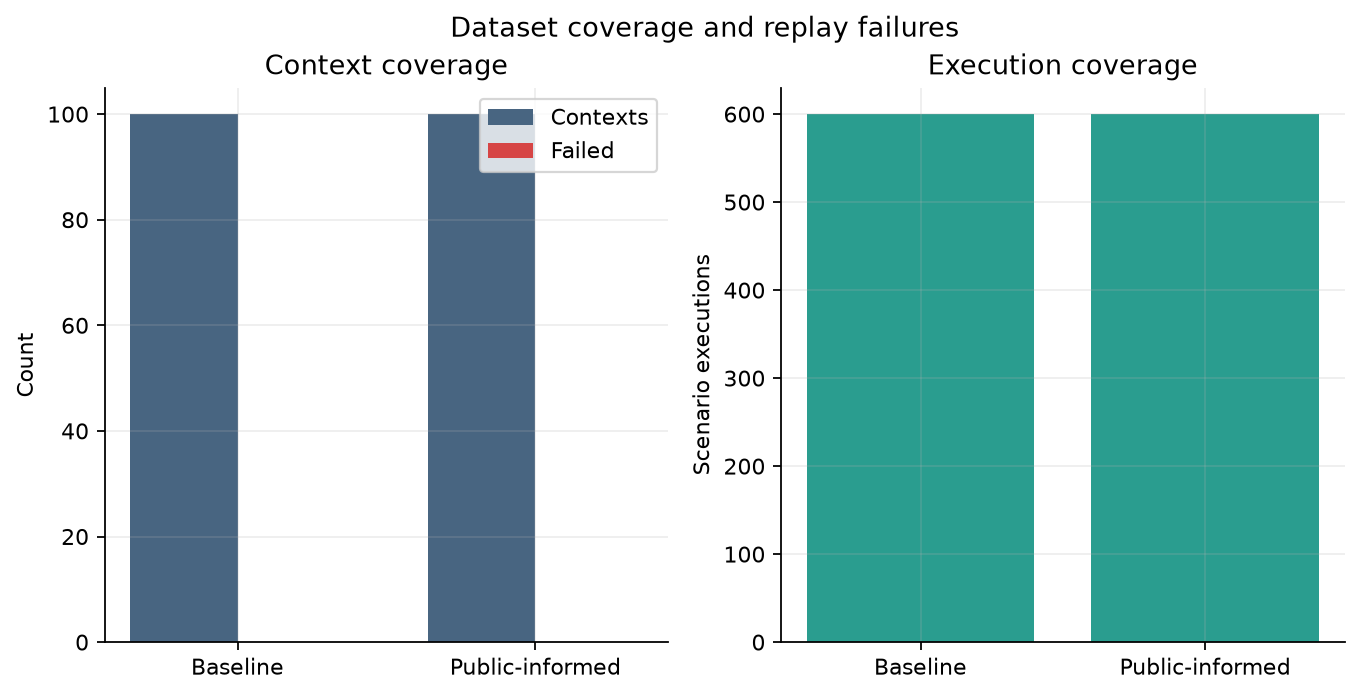

In [2]:
display(results['audit'])
display(results['coverage'])
display(Image(filename=str(TOPIC_ROOT / 'reports' / 'figures' / '01_dataset_coverage.png')))

## 3. RQ-C1: Mỗi actor làm được gì?

`winner_change_rate` và `delta_p_win` trả lời hai câu khác nhau. Chỉ số đầu cho biết outcome có đổi hay không. Chỉ số sau cho biết các thay đổi có tạo lợi thế ròng cho attacker hay không.

,family_label,capability,validity_rate,winner_change_rate,delta_p_win,liveness_status
0,Dice2Win-inspired safe reference,BUILDER_REORDER,1.0,0.0,0.00,NOT_APPLICABLE
1,Dice2Win-inspired safe reference,BUILDER_SELECTIVE_INCLUSION,1.0,0.0,0.00,NOT_CHECKED
2,Dice2Win-inspired safe reference,SEARCHER_ONLY,1.0,0.0,0.00,NOT_APPLICABLE
3,Fomo3D-inspired,BUILDER_REORDER,1.0,1.0,0.08,NOT_APPLICABLE
4,Fomo3D-inspired,BUILDER_SELECTIVE_INCLUSION,1.0,1.0,0.08,NOT_CHECKED
5,Fomo3D-inspired,SEARCHER_ONLY,1.0,0.0,0.00,NOT_APPLICABLE


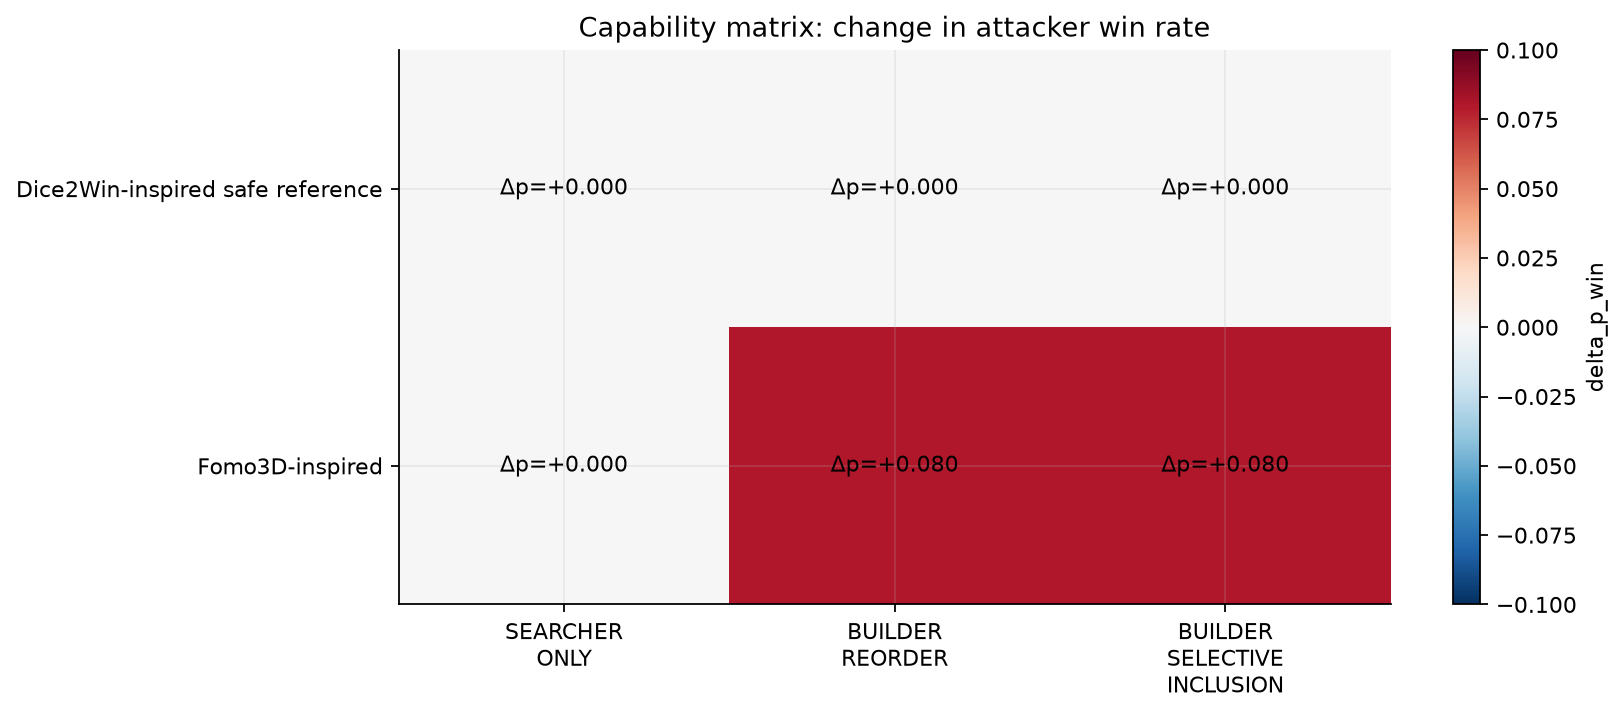

In [3]:
capability_columns = ['family_label', 'capability', 'validity_rate', 'winner_change_rate', 'delta_p_win', 'liveness_status']
display(results['public_summary'][capability_columns])
display(Image(filename=str(TOPIC_ROOT / 'reports' / 'figures' / '02_capability_matrix.png')))

## 4. RQ-C2: Canonical và counterfactual khác nhau bao nhiêu?

Khoảng tin cậy được tính trên paired outcome difference của từng context. Một interval chứa 0 không hỗ trợ kết luận rằng lợi thế xác suất là ổn định.

,family_label,capability,canonical_win_rate,manipulated_win_rate,delta_p_win,ci_95_low,ci_95_high,loss_to_win,win_to_loss,unchanged_win,unchanged_loss
0,Dice2Win-inspired safe reference,BUILDER_REORDER,0.51,0.51,0.00,0.00,0.00,0,0,51,49
1,Dice2Win-inspired safe reference,BUILDER_SELECTIVE_INCLUSION,0.51,0.51,0.00,0.00,0.00,0,0,51,49
2,Dice2Win-inspired safe reference,SEARCHER_ONLY,0.51,0.51,0.00,0.00,0.00,0,0,51,49
3,Fomo3D-inspired,BUILDER_REORDER,0.46,0.54,0.08,-0.12,0.28,54,46,0,0
4,Fomo3D-inspired,BUILDER_SELECTIVE_INCLUSION,0.46,0.54,0.08,-0.12,0.28,54,46,0,0
5,Fomo3D-inspired,SEARCHER_ONLY,0.46,0.46,0.00,0.00,0.00,0,0,46,54


,family_id,family_label,builder_capability,paired_contexts,capability_uplift,ci_95_low,ci_95_high
0,DICE2WIN_COMMIT_BLOCKHASH,Dice2Win-inspired safe reference,BUILDER_REORDER,100,0.00,0.00,0.00
1,DICE2WIN_COMMIT_BLOCKHASH,Dice2Win-inspired safe reference,BUILDER_SELECTIVE_INCLUSION,100,0.00,0.00,0.00
2,FOMO3D_PUBLIC_CONTEXT_HASH_MODULO,Fomo3D-inspired,BUILDER_REORDER,100,0.08,-0.12,0.28
3,FOMO3D_PUBLIC_CONTEXT_HASH_MODULO,Fomo3D-inspired,BUILDER_SELECTIVE_INCLUSION,100,0.08,-0.12,0.28


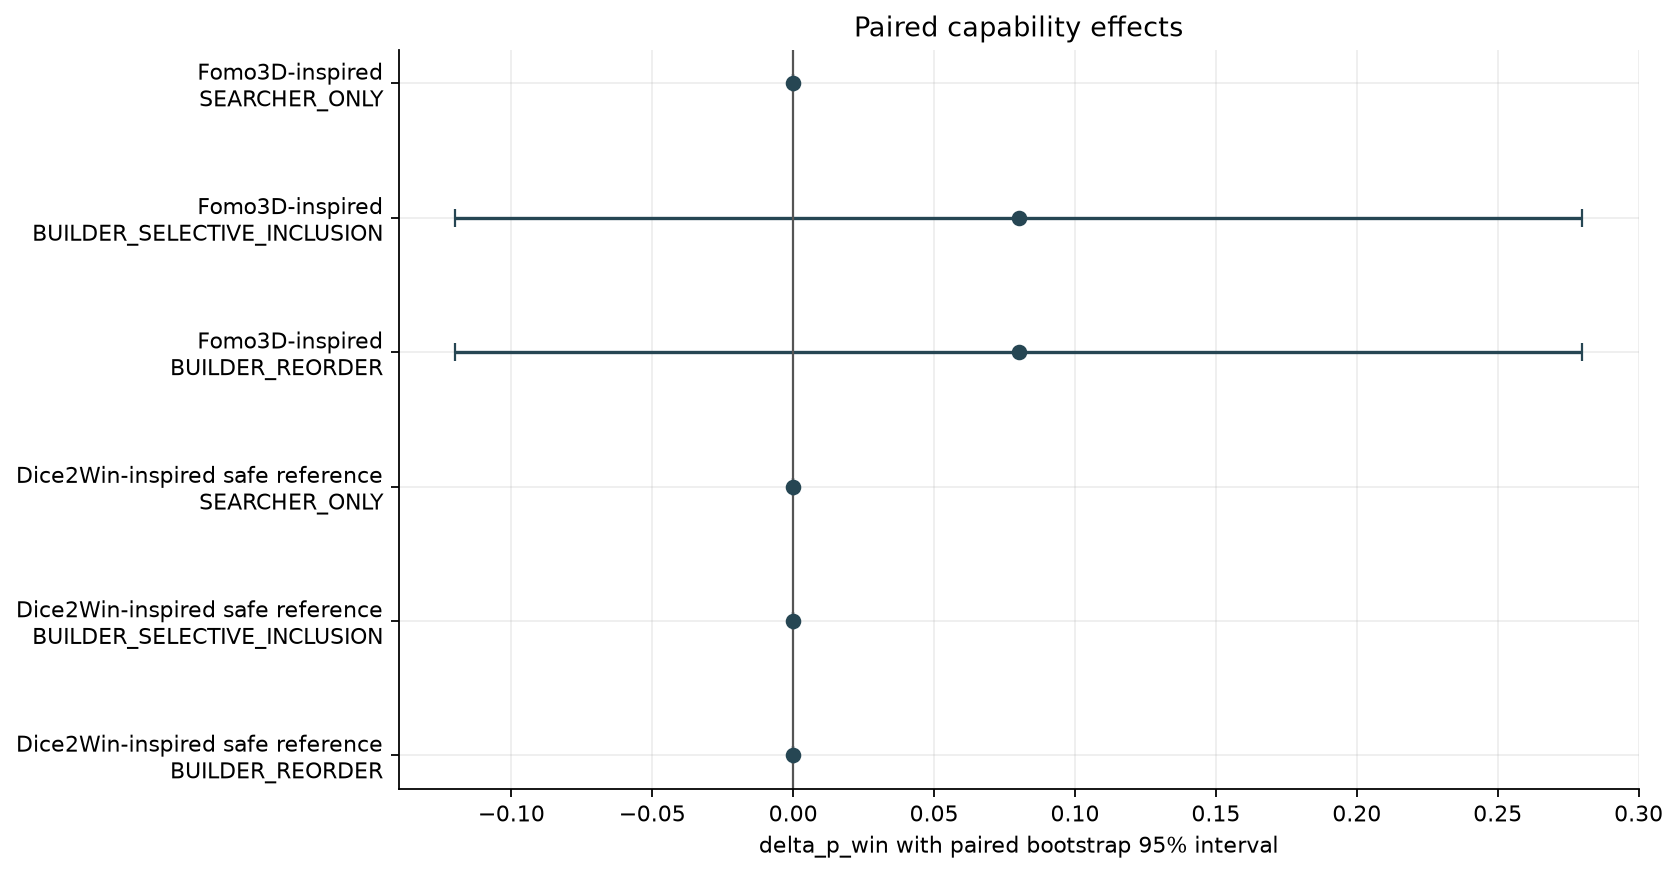

In [4]:
effect_columns = ['family_label', 'capability', 'canonical_win_rate', 'manipulated_win_rate', 'delta_p_win', 'ci_95_low', 'ci_95_high', 'loss_to_win', 'win_to_loss', 'unchanged_win', 'unchanged_loss']
display(results['public_summary'][effect_columns])
display(results['capability_uplift'])
display(Image(filename=str(TOPIC_ROOT / 'reports' / 'figures' / '03_paired_delta_ci.png')))

## 5. RQ-C3: Sensitivity kinh tế

Transaction fee đến từ replay. Bid bằng 0 và opportunity cost là giả định `MODELED`. Break-even chỉ được tính khi point estimate `delta_p_win > 0`; nó không phải bằng chứng về lợi nhuận lịch sử.

,family_label,capability,cost_model_id,delta_p_win,mean_total_cost_wei,net_profit_at_declared_prize_wei,break_even_prize_bnb,cost_evidence
0,Dice2Win-inspired safe reference,BUILDER_REORDER,FEE_ONLY,0.00,97895850000000,-97895850000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
1,Dice2Win-inspired safe reference,BUILDER_REORDER,OPPORTUNITY_BASE,0.00,293687550000000,-293687550000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
2,Dice2Win-inspired safe reference,BUILDER_REORDER,OPPORTUNITY_HIGH,0.00,489479250000000,-489479250000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
3,Dice2Win-inspired safe reference,BUILDER_REORDER,OPPORTUNITY_LOW,0.00,195791700000000,-195791700000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
4,Dice2Win-inspired safe reference,BUILDER_SELECTIVE_INCLUSION,FEE_ONLY,0.00,97895850000000,-97895850000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
5,Dice2Win-inspired safe reference,BUILDER_SELECTIVE_INCLUSION,OPPORTUNITY_BASE,0.00,293687550000000,-293687550000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
6,Dice2Win-inspired safe reference,BUILDER_SELECTIVE_INCLUSION,OPPORTUNITY_HIGH,0.00,489479250000000,-489479250000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
7,Dice2Win-inspired safe reference,BUILDER_SELECTIVE_INCLUSION,OPPORTUNITY_LOW,0.00,195791700000000,-195791700000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
8,Dice2Win-inspired safe reference,SEARCHER_ONLY,FEE_ONLY,0.00,80795850000000,-80795850000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY
9,Dice2Win-inspired safe reference,SEARCHER_ONLY,OPPORTUNITY_BASE,0.00,242387550000000,-242387550000000,NaN,REPLAYED_FEE_PLUS_MODELED_BID_AND_OPPORTUNITY


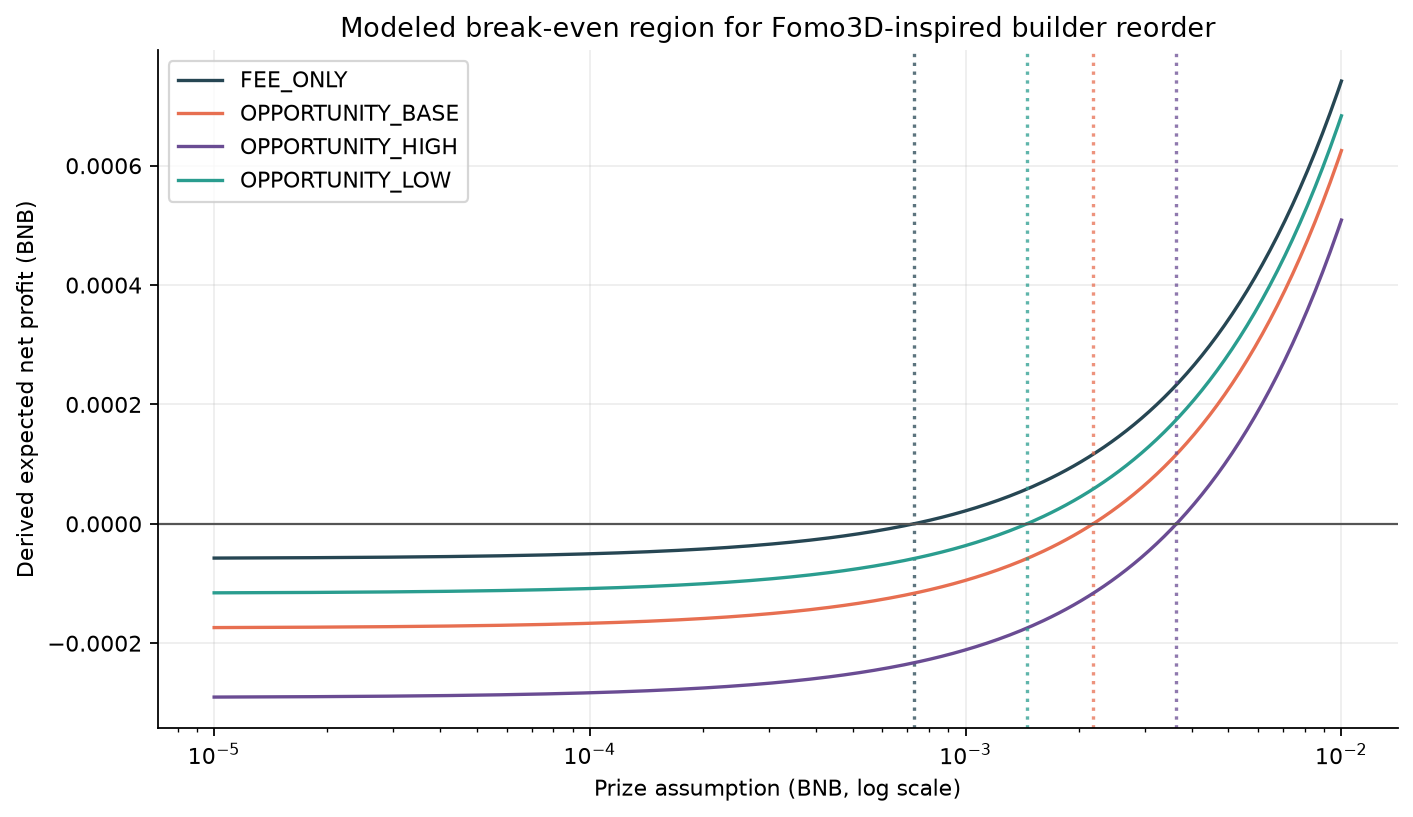

In [5]:
economic_columns = ['family_label', 'capability', 'cost_model_id', 'delta_p_win', 'mean_total_cost_wei', 'net_profit_at_declared_prize_wei', 'break_even_prize_bnb', 'cost_evidence']
display(results['economic_sensitivity'][economic_columns])
display(Image(filename=str(TOPIC_ROOT / 'reports' / 'figures' / '04_net_profit_sensitivity.png')))

## 6. RQ-C4: Weak rule và safe reference

Dice2Win-inspired giữ winner khi chỉ reorder, nhưng liên kết với deployed bytecode lịch sử vẫn mang trạng thái `RULE_UNCONFIRMED`.

,capability,paired_contexts,weak_delta_p_win,safe_delta_p_win,delta_reduction,ci_95_low,ci_95_high,safe_provenance_status
0,BUILDER_REORDER,100,0.08,0.0,0.08,-0.12,0.28,RULE_UNCONFIRMED
1,BUILDER_SELECTIVE_INCLUSION,100,0.08,0.0,0.08,-0.12,0.28,RULE_UNCONFIRMED
2,SEARCHER_ONLY,100,0.00,0.0,0.00,0.00,0.00,RULE_UNCONFIRMED


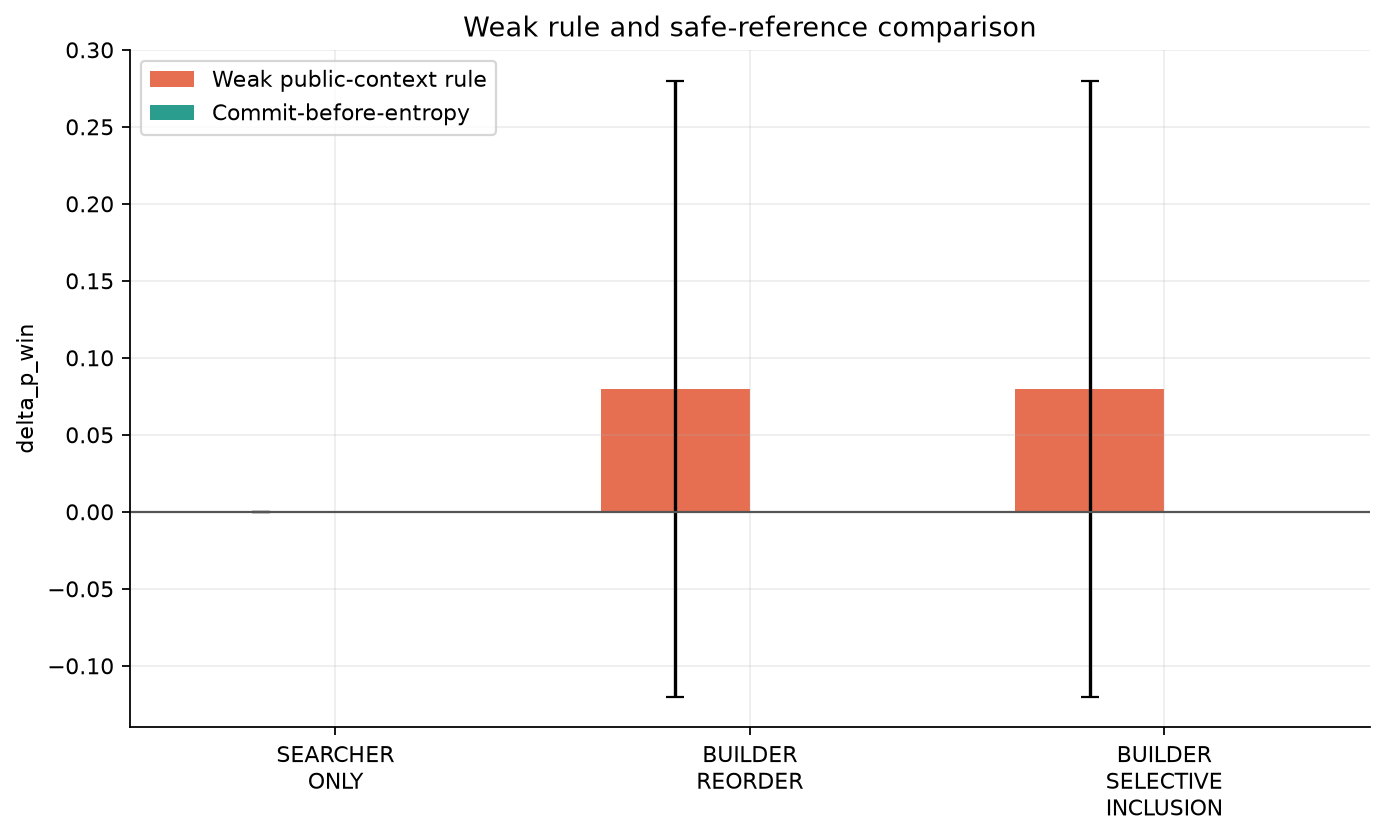

In [6]:
display(results['safe_reference'])
display(Image(filename=str(TOPIC_ROOT / 'reports' / 'figures' / '05_weak_vs_safe.png')))

## 7. So sánh với VERY_SIMPLE_RULES

Bảng này dùng cùng 100 context để kiểm tra kết luận có đổi khi thay rule rất đơn giản bằng rule synthetic có provenance.

In [7]:
display(results['baseline_comparison'])

,public_family_id,baseline_family_id,capability,paired_contexts,baseline_delta_p_win,public_delta_p_win,difference,ci_95_low,ci_95_high
0,DICE2WIN_COMMIT_BLOCKHASH,COMMIT_BEFORE_ENTROPY,BUILDER_REORDER,100,0.00,0.00,0.00,0.00,0.0000
1,DICE2WIN_COMMIT_BLOCKHASH,COMMIT_BEFORE_ENTROPY,BUILDER_SELECTIVE_INCLUSION,100,0.00,0.00,0.00,0.00,0.0000
2,DICE2WIN_COMMIT_BLOCKHASH,COMMIT_BEFORE_ENTROPY,SEARCHER_ONLY,100,0.00,0.00,0.00,0.00,0.0000
3,FOMO3D_PUBLIC_CONTEXT_HASH_MODULO,WEAK_PUBLIC_CONTEXT,BUILDER_REORDER,100,0.00,0.08,0.08,-0.12,0.2800
4,FOMO3D_PUBLIC_CONTEXT_HASH_MODULO,WEAK_PUBLIC_CONTEXT,BUILDER_SELECTIVE_INCLUSION,100,0.04,0.08,0.04,-0.24,0.3005
5,FOMO3D_PUBLIC_CONTEXT_HASH_MODULO,WEAK_PUBLIC_CONTEXT,SEARCHER_ONLY,100,0.00,0.00,0.00,0.00,0.0000


## 8. Kết luận và giới hạn

- RQ-C1: Searcher-only không đổi winner. Builder reorder và declared selective inclusion đổi winner trong Fomo3D-inspired workload.
- RQ-C2: Point estimate của hai builder capability là `+0.080`, nhưng interval 95% chứa 0.
- RQ-C3: Có thể tính break-even có điều kiện từ point estimate và named cost model. Không được gọi đây là lợi nhuận thực tế.
- RQ-C4: Commit-before-entropy giữ outcome trước thay đổi order trong abstraction đã replay.

Workload chỉ có hai transaction liên quan. Selective inclusion chưa đo liveness. Batch 2, 5 và 10 participant chưa chạy.

In [8]:
assert (results['audit']['status'] == 'PASS').all()
assert len(results['public_summary']) == 6
assert len(results['economic_sensitivity']) == 24
assert len(results['safe_reference']) == 3
print('STEP 11 ANALYSIS: PASS')
print('Chi tiết: reports/results_by_rq.md và reports/robustness_checks.md')

STEP 11 ANALYSIS: PASS
Chi tiết: reports/results_by_rq.md và reports/robustness_checks.md
